In [82]:
import cdsapi
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cf


from eofs.xarray import Eof


In [83]:
def _time_as_float(time: xr.DataArray, time_dim: str) -> xr.DataArray:
    # numeric seconds since first timestamp (keeps numbers small)
    return (time - time.isel({time_dim: 0})).astype("timedelta64[s]").astype("int64").astype("float64")

def linear_detrend(obj: xr.DataArray | xr.Dataset, time_dim: str = "time") -> xr.DataArray | xr.Dataset:
    """
    Remove a linear trend y ~ s*(t - t̄_valid) + ȳ_valid at each grid point.
    Closed-form LS using reductions; dask-friendly; handles NaNs.
    """
    t = _time_as_float(obj[time_dim], time_dim)  # (time,)
    def _detrend_da(da: xr.DataArray) -> xr.DataArray:
        da = da.sortby(time_dim).astype("float32")
        if hasattr(da.data, "chunks"):
            da = da.chunk({time_dim: -1})  # one chunk along time
        mask = da.notnull()                                # (time, ...)
        t_b = t.broadcast_like(da)                         # (time, ...)
        t_mean_valid = t_b.where(mask).mean(time_dim, skipna=True)
        tc = t_b - t_mean_valid                            # centered time per point
        num = (da * tc).sum(time_dim, skipna=True)
        den = (tc**2).sum(time_dim, skipna=True)
        slope = xr.where(den > 0, num / den, 0.0)
        ybar  = da.mean(time_dim, skipna=True)
        trend = slope * (t_b - t_mean_valid) + ybar
        return (da - trend).astype("float32")
    return obj.map(_detrend_da) if isinstance(obj, xr.Dataset) else _detrend_da(obj)

def monthly_anom_and_z(
    detr: xr.DataArray | xr.Dataset,
    time_dim: str = "time",
    base_period: tuple[str, str] | None = None,
    ddof: int = 1,
    eps: float = 1e-6,
):
    """
    From linearly-detrended data, remove monthly climatology and compute monthly z-scores.
    Returns (anom, z). Works for Dataset or DataArray.
    """
    clim_src = detr if base_period is None else detr.sel({time_dim: slice(*base_period)})
    key = f"{time_dim}.month"

    clim_mean = clim_src.groupby(key).mean(time_dim, skipna=True)
    anom = detr.groupby(key) - clim_mean

    clim_std = clim_src.groupby(key).std(time_dim, skipna=True, ddof=ddof)
    safe_std = xr.where(clim_std > eps, clim_std, np.nan)
    z = anom.groupby(key) / safe_std
    return anom, z



In [ ]:
dataset = "reanalysis-era5-single-levels-monthly-means"
request = {
    "product_type": ["monthly_averaged_reanalysis"],
    "year": [
        "1979", "1980", "1981",
        "1982", "1983", "1984",
        "1985", "1986", "1987",
        "1988", "1989", "1990",
        "1991", "1992", "1993",
        "1994", "1995", "1996",
        "1997", "1998", "1999",
        "2000", "2001", "2002",
        "2003", "2004", "2005",
        "2006", "2007", "2008",
        "2009", "2010", "2011",
        "2012", "2013", "2014",
        "2015", "2016", "2017",
        "2018", "2019", "2020",
        "2021", "2022", "2023",
        "2024"
    ],
    "month": [
        "01", "02", "03",
        "04", "05", "06",
        "07", "08", "09",
        "10", "11", "12"
    ],
    "time": ["00:00"],
    "data_format": "grib",
    "download_format": "unarchived",
    "variable": [
        "sea_surface_temperature",
        "total_column_rain_water"
    ],
    "area": [65, 120, -65, -60]
}

client = cdsapi.Client()
client.retrieve(dataset, request).download()


In [84]:
ds = xr.open_dataset('467b3d22b9b1d0ecb3d506c52fa27b35.grib', engine = 'cfgrib')

c:\Users\12ian\anaconda3\envs\ATMS523-env\Lib\site-packages\cfgrib\xarray_plugin.py:132: FutureWarning: In a future version of xarray decode_timedelta will default to False rather than None. To silence this warning, set decode_timedelta to True, False, or a 'CFTimedeltaCoder' instance.
  vars, attrs, coord_names = xr.conventions.decode_cf_variables(


In [85]:
ds

<xarray.Dataset> Size: 2GB
Dimensions:     (time: 552, latitude: 521, longitude: 721)
Coordinates:
    number      int64 8B ...
  * time        (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2024-12-01
    step        timedelta64[ns] 8B ...
    surface     float64 8B ...
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude   (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0
    valid_time  (time) datetime64[ns] 4kB ...
Data variables:
    sst         (time, latitude, longitude) float32 829MB ...
    tcrw        (time, latitude, longitude) float32 829MB ...
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-10-20T12:48 GRIB to CDM+CF via cfgrib-0.9.1...

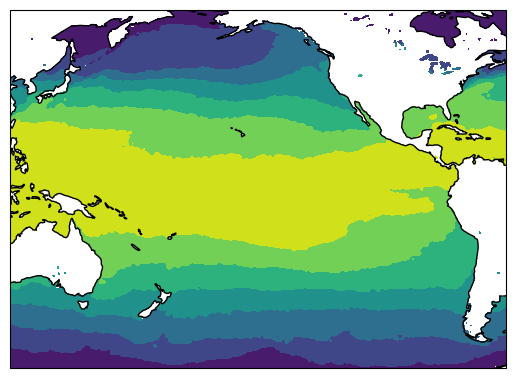

In [86]:
snapshot = ds['sst'].isel(time = 100).values

lat_grid, lon_grid = np.meshgrid(ds.longitude.values, ds.latitude.values)

fig, ax = plt.subplots(subplot_kw={'projection': ccrs.PlateCarree(central_longitude=-180)})
ax.contourf(lat_grid, lon_grid, snapshot, transform = ccrs.PlateCarree())
ax.coastlines()


In [87]:
detrended_data = linear_detrend(ds)

In [88]:
anom_data, z = monthly_anom_and_z(detrended_data)

In [89]:
anom_data

<xarray.Dataset> Size: 2GB
Dimensions:     (time: 552, latitude: 521, longitude: 721)
Coordinates:
    number      (time) int64 4kB 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0 0
  * time        (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2024-12-01
    step        (time) timedelta64[ns] 4kB 00:00:00 00:00:00 ... 00:00:00
    surface     (time) float64 4kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude   (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0
    valid_time  (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2024-12-01
    month       (time) int64 4kB 1 2 3 4 5 6 7 8 9 10 ... 3 4 5 6 7 8 9 10 11 12
Data variables:
    sst         (time, latitude, longitude) float32 829MB nan nan ... nan nan
    tcrw        (time, latitude, longitude) float32 829MB -0.0001407 ... -9.8...

In [90]:
# Create an EOF solver to do the EOF analysis. Square-root of cosine of
# latitude weights are applied before the computation of EOFs.
coslat = np.cos(np.deg2rad(anom_data.coords['latitude'].values))
wgts = np.sqrt(coslat)[..., np.newaxis]
solver = Eof(anom_data['sst'], weights=wgts)

In [91]:
# Retrieve the leading n EOFs, expressed as the correlation between the leading
# PC time series and the input SST anomalies at each grid point, and the
# leading PC time series itself.

neofs = 5
eofs = solver.eofsAsCorrelation(neofs = neofs)
pcs = solver.pcs(npcs = neofs, pcscaling=1)

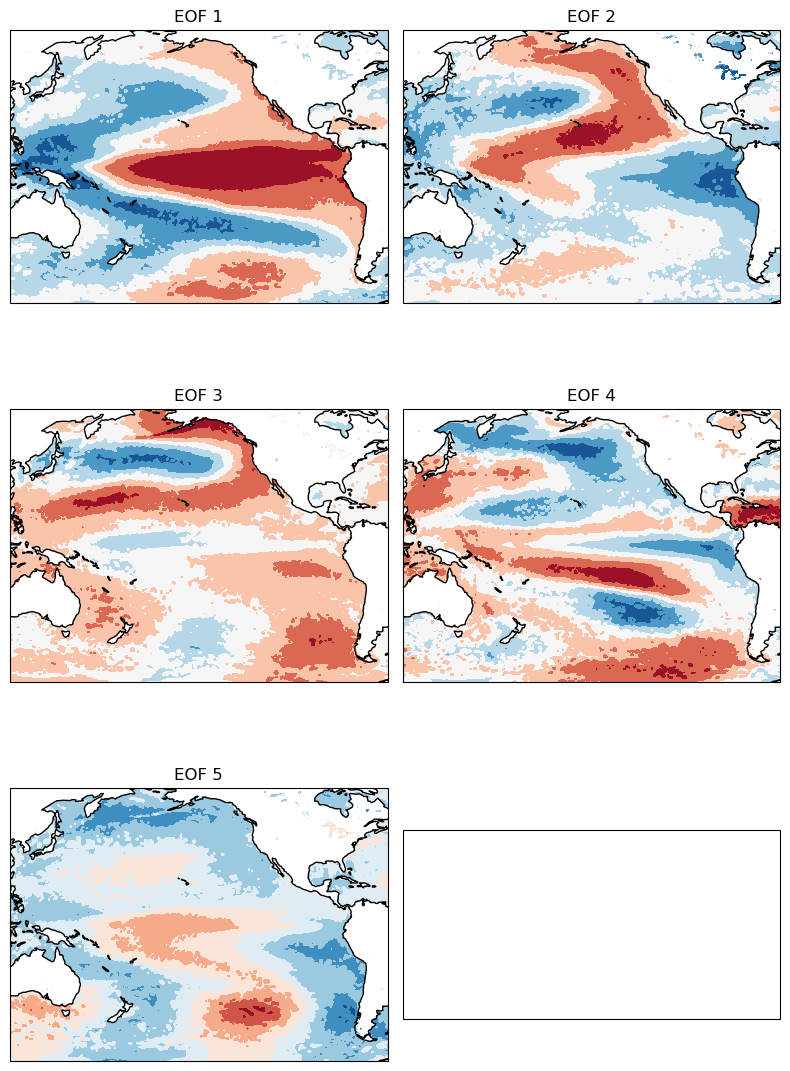

In [94]:
lat_grid, lon_grid = np.meshgrid(anom_data.longitude.values, anom_data.latitude.values)

n = 0; nrows = 3; ncols = 2

fig, ax = plt.subplots(nrows = 3, ncols = 2,figsize = (8,12), subplot_kw={'projection': ccrs.PlateCarree(central_longitude=-180)})

for i in range(nrows):
    for j in range(ncols):    
        ax[i,j].contourf(lat_grid, lon_grid, eofs[n,:,:], cmap = 'RdBu_r', transform = ccrs.PlateCarree())
        ax[i,j].coastlines()
        n+=1
        ax[i,j].set_title("EOF " + str(n))
        
        if n == neofs:
            fig.tight_layout()
            break
        



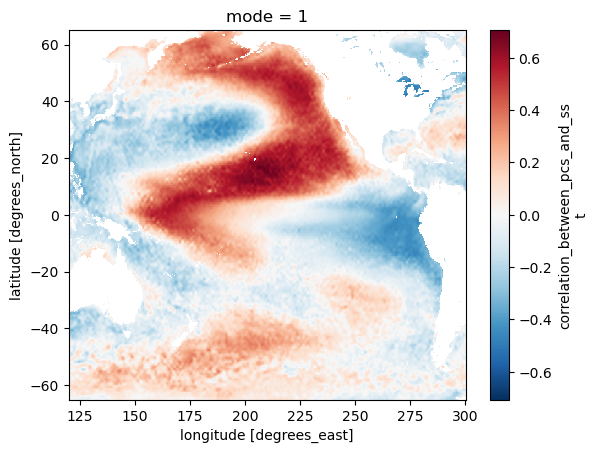

In [95]:
eofs.isel(mode = 1).plot()

(4.464185504550119e-16, 0.24132316768169404)

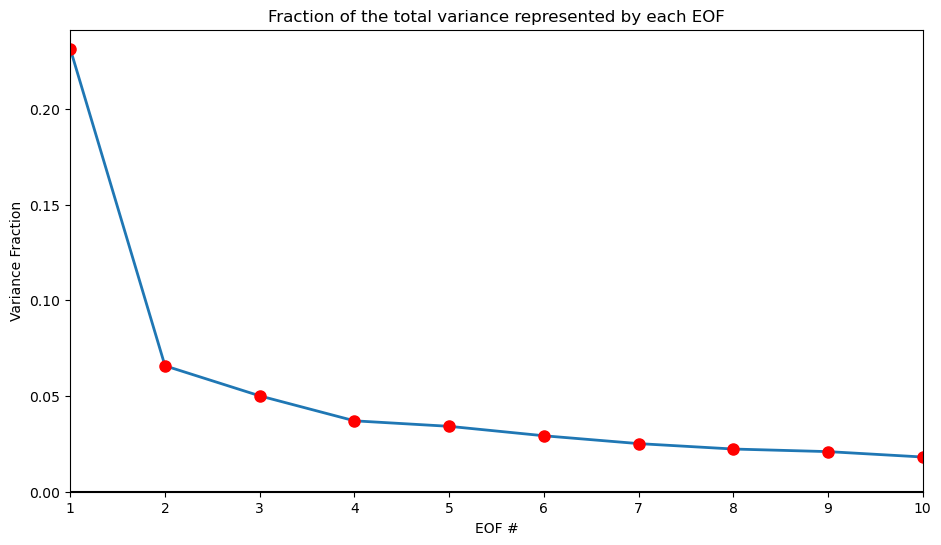

In [96]:
varfrac = solver.varianceFraction()

# Plot the fraction of variance explained by each EOF
plt.figure(figsize=(11,6))
eof_num = range(1, 11)
plt.plot(eof_num, varfrac[0:10], linewidth=2)
plt.plot(eof_num, varfrac[0:10], linestyle='None', marker="o", color='r', markersize=8)
plt.axhline(0, color='k')
plt.xticks(range(1, 11))
plt.title('Fraction of the total variance represented by each EOF')
plt.xlabel('EOF #')
plt.ylabel('Variance Fraction')
plt.xlim(1, 10)
plt.ylim(np.min(varfrac), np.max(varfrac)+0.01)

In [97]:
reconstruction = solver.reconstructedField(neofs)
reconstruction

<xarray.DataArray 'sst' (time: 552, latitude: 521, longitude: 721)> Size: 829MB
array([[[        nan,         nan,         nan, ...,  0.26682994,
          0.27596572,  0.28518283],
        [        nan,         nan,         nan, ...,  0.271885  ,
          0.2747866 ,  0.27569774],
        [        nan,         nan,         nan, ...,  0.3026714 ,
          0.2974902 ,  0.29229432],
        ...,
        [-0.01964998, -0.02495277, -0.03029654, ...,         nan,
                 nan,         nan],
        [-0.02006874, -0.02406432, -0.02803234, ...,         nan,
                 nan,         nan],
        [-0.0233586 , -0.02726935, -0.03119792, ...,         nan,
                 nan,         nan]],

       [[        nan,         nan,         nan, ...,  0.35587996,
          0.36861825,  0.38157293],
        [        nan,         nan,         nan, ...,  0.36286575,
          0.36447456,  0.36562487],
        [        nan,         nan,         nan, ...,  0.3818962 ,
          0.3814935 ,  0.3810574 ],
...
        [-0.02014011, -0.02331016, -0.02640076, ...,         nan,
                 nan,         nan],
        [-0.02316328, -0.02502652, -0.02689593, ...,         nan,
                 nan,         nan],
        [-0.02554063, -0.02665262, -0.02711658, ...,         nan,
                 nan,         nan]],

       [[        nan,         nan,         nan, ...,  0.13792564,
          0.14300558,  0.14803581],
        [        nan,         nan,         nan, ...,  0.14651448,
          0.15065205,  0.15450644],
        [        nan,         nan,         nan, ...,  0.17162845,
          0.17452388,  0.17736873],
        ...,
        [-0.01693936, -0.01718851, -0.01742575, ...,         nan,
                 nan,         nan],
        [-0.0208763 , -0.02123897, -0.02160095, ...,         nan,
                 nan,         nan],
        [-0.02232257, -0.02318068, -0.02467321, ...,         nan,
                 nan,         nan]]], shape=(552, 521, 721), dtype=float32)
Coordinates:
  * time        (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2024-12-01
  * latitude    (latitude) float64 4kB 65.0 64.75 64.5 ... -64.5 -64.75 -65.0
  * longitude   (longitude) float64 6kB 120.0 120.2 120.5 ... 299.5 299.8 300.0
    number      (time) int64 4kB 0 0 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0 0 0 0
    step        (time) timedelta64[ns] 4kB 00:00:00 00:00:00 ... 00:00:00
    surface     (time) float64 4kB 0.0 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0 0.0
    valid_time  (time) datetime64[ns] 4kB 1979-01-01 1979-02-01 ... 2024-12-01
    month       (time) int64 4kB 1 2 3 4 5 6 7 8 9 10 ... 3 4 5 6 7 8 9 10 11 12
Attributes:
    long_name:  sst_reconstructed_with_5_EOFs

In [98]:
eof_eval = xr.corr(ds['sst'], reconstruction, dim = 'time')

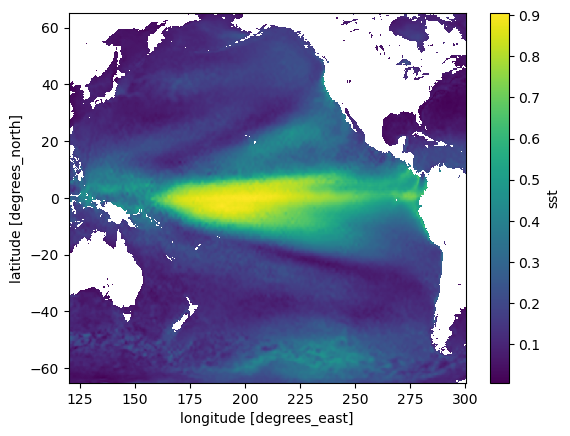

In [99]:
eof_eval.plot()

In [104]:
reconstruction1 = solver.reconstructedField(1)
precip_cor = xr.corr(reconstruction1, ds['tcrw'], dim = 'time')

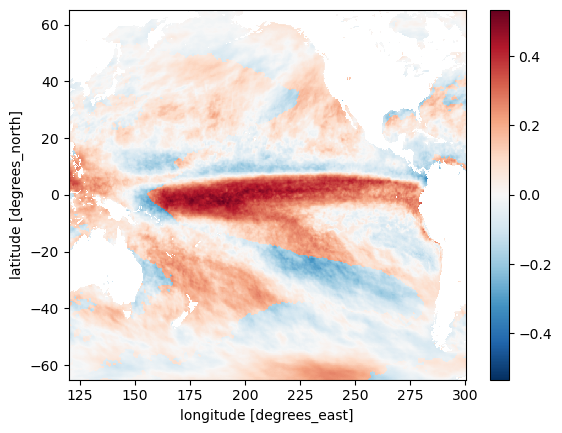

In [105]:
precip_cor.plot()